# **PHAS0102 Assignment 1** 
**-- Matrix-matrix multiplication**
---
# **Part 1:** A Better Function


## **The original algorithm:**

In [21]:
import numpy as np

# 3 loop (not good)
def slow_matrix_product(mat1, mat2):
    """Multiply two matrices."""

    # Check whether the matrix dimensions are compatible
    assert mat1.shape[1] == mat2.shape[0]

    # Create an empty list to store the result
    result = []


    for c in range(mat2.shape[1]): # Loop through each column of 2nd matrix
        column = []
        for r in range(mat1.shape[0]): # Loop through each row of 1st matrix
            value = 0
            for i in range(mat1.shape[1]): # dot product row r and column c
                value += mat1[r, i] * mat2[i, c]
            column.append(value) # Add the completed value to the current column
        result.append(column) # Add the completed column to the result
    return np.array(result).transpose()
    # transpose is used to convert the matrix list

# Define 2 random 10x10 matrix
matrix1 = np.random.rand(10, 10)
matrix2 = np.random.rand(10, 10)

print(slow_matrix_product(matrix1, matrix2))
print()
print()
print(matrix1 @ matrix2)

[[1.34438133 2.18135684 1.97555967 1.92967365 1.57799096 0.98405663
  1.81916073 1.37558246 2.20594323 2.07245943]
 [1.31771216 1.51695872 1.9410572  1.73478072 1.39870366 1.73681811
  1.76549313 2.22094082 2.38633521 2.29333981]
 [2.87301955 2.45337517 3.24682478 3.45680924 2.80886616 2.05699867
  2.61501511 2.96799841 3.82197684 3.3049185 ]
 [2.71356925 2.31743372 3.08625831 3.34623164 2.33204069 1.46494158
  2.36590162 2.81552303 3.45587617 3.01739551]
 [2.00460254 2.32736086 2.67135179 2.53396222 2.17010684 1.61459301
  2.19822941 2.55811322 3.11448761 2.84261867]
 [2.78036451 1.9347404  3.05380368 3.54033635 2.33190609 2.0566168
  2.48092113 3.28363193 3.7244074  3.33764404]
 [2.36478992 2.65744305 2.75383272 3.26363186 2.27677187 1.27028574
  2.32835212 2.06742557 2.92130089 2.53138343]
 [2.74089649 3.09929875 3.32731931 3.25881511 3.03779124 2.48226143
  2.78362771 3.52114734 4.0364904  3.45667712]
 [3.22244304 2.93115695 3.01679379 3.60149751 2.26032675 2.25666613
  2.47941061 

#### We can find that the 2 results are same.

#### I use AI to make detailed explanation on the slow_matrix_product()

---

## **1.1 The improved algorithm:** faster_matrix_product( ):, 
### which is better than the original one.

### **Reason 1:** The **faster_matrix_product( )** uses a more advanced method to operate matrix multiplication than the **slow_matrix_product( )**, by reducing the number of the loops from **3** to **2**, which uses **np.dot( )** to replace the 3rd layer of loop. Therefore, the **faster_matrix_product( )** is expected to spend less execution time by reducing Python interpreter overhead， and improving practical execution efficiency.

### **Reason 2:** Since the new function has fewer lines, it will be easier to read and maintain. It uses **value = np.dot(mat1[r, :], mat2[:, c])** to replace the innermost loop, simplifying the computational process by dot-producting a row of the 1st matrix and a column of the 2nd matrix, which also accords with the calculation process in mathematics.

In [22]:
def faster_matrix_product(mat1, mat2):
    
    assert mat1.shape[1] == mat2.shape[0]
    # Check whether the matrix dimensions are compatible
    
    result = []

    for c in range(mat2.shape[1]):  # Loop over each column of the result matrix
        column = []

        for r in range(mat1.shape[0]):  # Loop over each row of the result matrix
            value = np.dot(mat1[r, :], mat2[:, c])
            column.append(value)

        result.append(column)

    return np.array(result).transpose()

---

## **1.2 Correctness Tests**

In [3]:
for n in range(2, 6):
    # Define 2 matrix
    A = np.random.rand(n, n) 
    B = np.random.rand(n, n)

    assert np.allclose(faster_matrix_product(A, B), A @ B)  #Make comparison

    print(f"{n}x{n} matrix: **Passed!** \n")

2x2 matrix: **Passed!** 

3x3 matrix: **Passed!** 

4x4 matrix: **Passed!** 

5x5 matrix: **Passed!** 



#### A test to ensure my system can run correctly

---

## **1.3 Performance Comparison**

#### This part will compares the exexution times of **slow_matrix_product(mat1, mat2)** and **faster_matrix_product(mat1, mat2)** in different sizes of matrices from 10x10 to 1000x1000.

#### A test on 100x100 matrix

In [4]:
# A test on 100x100 matrix
import time
A = np.random.rand(100, 100)
B = np.random.rand(100, 100)

# Measure the original function
start = time.perf_counter()
slow_matrix_product(A, B)
slow_time = time.perf_counter() - start

# Measure the improved function
start = time.perf_counter()
faster_matrix_product(A, B)
fast_time = time.perf_counter() - start

print(f"slow_matrix_product(): {slow_time:.6f} s")
print(f"faster_matrix_product(): {fast_time:.6f} s")

slow_matrix_product(): 0.404721 s
faster_matrix_product(): 0.014733 s


#### I tried my best, but still not familiar with the grammar of calculating the time, so I asked AI for help.

### The entire performance comparison

10x10: Slow = 0.0005s, Fast = 0.0002s
30x30: Slow = 0.0135s, Fast = 0.0026s
50x50: Slow = 0.0639s, Fast = 0.0035s
80x80: Slow = 0.2168s, Fast = 0.0108s
100x100: Slow = 0.4125s, Fast = 0.0140s
300x300: Slow = 9.7765s, Fast = 0.1501s
500x500: Slow = 44.9747s, Fast = 0.5372s
600x600: Slow = 81.7112s, Fast = 0.6881s
700x700: Slow = 125.1024s, Fast = 1.0359s
800x800: Slow = 180.0847s, Fast = 1.4556s
900x900: Slow = 269.4202s, Fast = 1.8988s
1000x1000: Slow = 365.6507s, Fast = 2.2610s


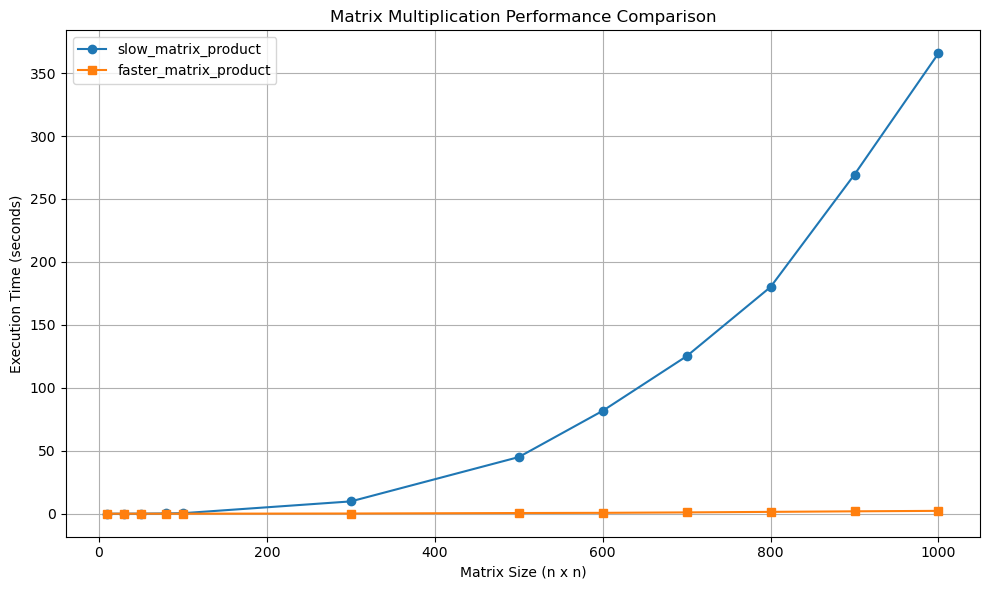

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import time

sizes = [10, 30, 50, 80, 100, 300, 500, 600, 700, 800, 900, 1000]

def compare_matrix_performance(sizes):
    slow_times = []
    fast_times = []

    for n in sizes:
        # Generate 2  nxn matrix
        A = np.random.rand(n, n)
        B = np.random.rand(n, n)

        # Measure slow_matrix_product
        start = time.perf_counter()
        slow_matrix_product(A, B)
        slow_time = time.perf_counter() - start

        # Measure faster_matrix_product
        start = time.perf_counter()
        faster_matrix_product(A, B)
        fast_time = time.perf_counter() - start

        # Store execution times
        slow_times.append(slow_time)
        fast_times.append(fast_time)

        print(f"{n}x{n}: Slow = {slow_time:.4f}s, Fast = {fast_time:.4f}s", flush=True)

    # Plot the result
    plt.figure(figsize=(10, 6))

    plt.plot(sizes, slow_times, marker='o', label='slow_matrix_product')
    plt.plot(sizes, fast_times, marker='s', label='faster_matrix_product')

    plt.xlabel('Matrix Size (n x n)')
    plt.ylabel('Execution Time (seconds)')
    plt.title('Matrix Multiplication Performance Comparison')

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return slow_times, fast_times

# Run the benchmark and plot the results
slow_times, fast_times = compare_matrix_performance(sizes)


#### The line chart for comparison

#### We can find that, although the two functions are essentially all of the complexity n^3, faster_matrix_product( ) is much faster since it reduces the Python interpreter overhead.

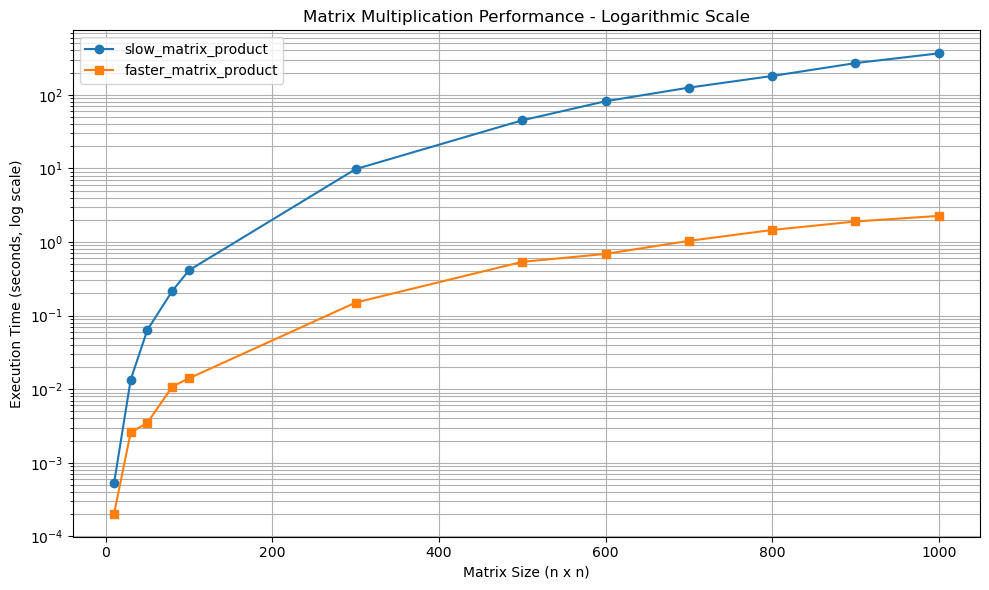

In [6]:
# Figure 2: Logarithmic Scale only for the Execution time axis

plt.figure(figsize=(10, 6))

plt.plot(sizes, slow_times, marker='o', label='slow_matrix_product')
plt.plot(sizes, fast_times, marker='s', label='faster_matrix_product')

# Set the Y-axis to logarithmic scale
plt.yscale('log')

plt.xlabel('Matrix Size (n x n)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Matrix Multiplication Performance - Logarithmic Scale')

plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

### If I want to make the line chart linear, I may make the Matrix Size axis into log format.⬇️

---

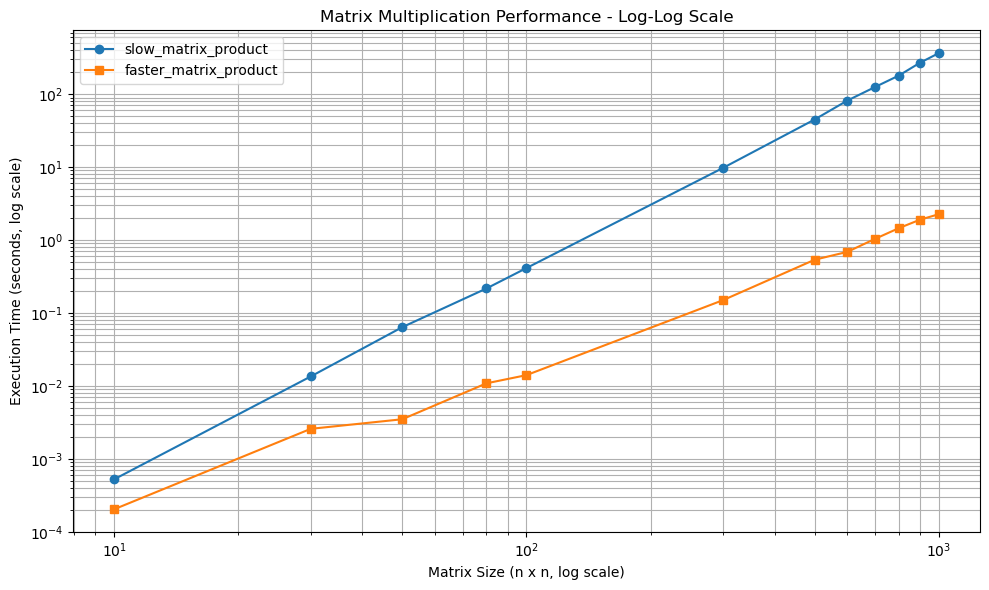

In [8]:
import matplotlib.pyplot as plt
# Figure 3: Logarithmic scale for both axes
plt.figure(figsize=(10, 6))

plt.plot(sizes, slow_times, marker='o', label='slow_matrix_product')
plt.plot(sizes, fast_times, marker='s', label='faster_matrix_product')

plt.xscale('log') # also the x axis
plt.yscale('log')

plt.xlabel('Matrix Size (n x n, log scale)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Matrix Multiplication Performance - Log-Log Scale')

plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

---

# **Part 2:** Speeding it up with Numba

## **2.1 Numba JIT Compilation**

In [38]:
import numpy as np
from numba import njit

@njit
def faster_matrix_product_usingnumba(mat1,mat2):
    assert mat1.shape[1] == mat2.shape[0]
    
    result = np.empty((mat1.shape[0], mat2.shape[1])) # Create a result matrix in advance
                                                      # shape[0] means the number of Rows
                                                      # shape[1] means the number of Columns
    for c in range(mat2.shape[1]):
        for r in range(mat1.shape[0]):
            value = np.dot(mat1[r,:], mat2[:,c])      # mat1[r, :] --> Extract all the numbers in 
                                                      # the rth row of mat1
                                                      # mat1[:, c] --> Extract all the numbers in 
                                                      # the cth column of mat2
            result[r,c] = value

    return result

####  A verification on whether the Numba function is correct.

In [39]:
# Test the Numba function
A = np.random.rand(3, 3)
B = np.random.rand(3, 3)

numba_result = faster_matrix_product_usingnumba(A, B)
numpy_result = A @ B

assert np.allclose(numba_result, numpy_result)

print("Numba correctness test: **Passed!**")

Numba correctness test: **Passed!**


## **2.2 Performance Comparison**

In [40]:
import time

def measure_time(func, A, B):
    times = []

    for i in range(5): #repeat 5 times
        start = time.perf_counter()
        func(A, B)
        end = time.perf_counter()

        times.append(end - start)

    return np.median(times) # return the median from 5 numbers

10x10: faster_matrix_product=0.0003s, faster_matrix_product_usingnumba=0.0000s, A @ B=0.000004s
30x30: faster_matrix_product=0.0025s, faster_matrix_product_usingnumba=0.0003s, A @ B=0.000009s
50x50: faster_matrix_product=0.0061s, faster_matrix_product_usingnumba=0.0003s, A @ B=0.000076s
80x80: faster_matrix_product=0.0107s, faster_matrix_product_usingnumba=0.0016s, A @ B=0.000158s
100x100: faster_matrix_product=0.0179s, faster_matrix_product_usingnumba=0.0018s, A @ B=0.000113s
300x300: faster_matrix_product=0.1741s, faster_matrix_product_usingnumba=0.0344s, A @ B=0.001060s
500x500: faster_matrix_product=0.5189s, faster_matrix_product_usingnumba=0.1309s, A @ B=0.003131s
600x600: faster_matrix_product=0.7272s, faster_matrix_product_usingnumba=0.2637s, A @ B=0.005914s
700x700: faster_matrix_product=1.1021s, faster_matrix_product_usingnumba=0.4160s, A @ B=0.007279s
800x800: faster_matrix_product=1.4466s, faster_matrix_product_usingnumba=0.6952s, A @ B=0.010922s
900x900: faster_matrix_produ

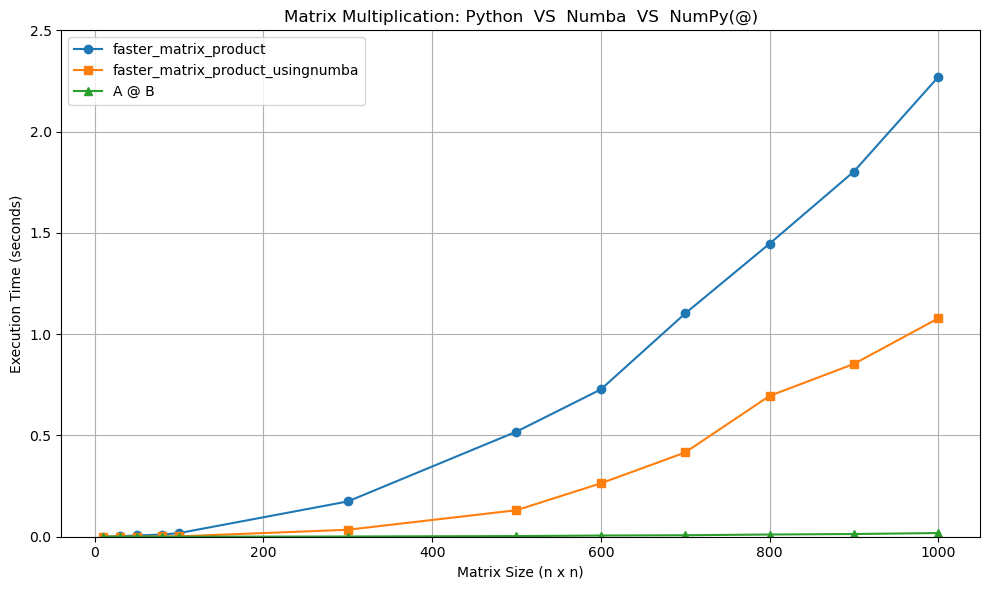

In [41]:
import matplotlib.pyplot as plt
sizes_part2 = [10, 30, 50, 80, 100, 300,
               500, 600, 700, 800, 900, 1000]

python_times = []
numba_times = []
numpy_times = []

for n in sizes_part2:
    A = np.random.rand(n, n)
    B = np.random.rand(n, n)

    python_t = measure_time(faster_matrix_product, A, B)
    numba_t = measure_time(faster_matrix_product_usingnumba, A, B)
    numpy_t = measure_time(lambda A, B: A @ B, A, B)

    python_times.append(python_t)
    numba_times.append(numba_t)
    numpy_times.append(numpy_t)

    print(f"{n}x{n}: faster_matrix_product={python_t:.4f}s, "
      f"faster_matrix_product_usingnumba={numba_t:.4f}s, "
      f"A @ B={numpy_t:.6f}s",
      flush=True)

# Plot the results
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, python_times, marker='o',
         label='faster_matrix_product')

plt.plot(sizes_part2, numba_times, marker='s',
         label='faster_matrix_product_usingnumba')

plt.plot(sizes_part2, numpy_times, marker='^',
         label='A @ B')

plt.ylim(0, 2.5)  

plt.xlabel('Matrix Size (n x n)')
plt.ylabel('Execution Time (seconds)')
plt.title('Matrix Multiplication: Python  VS  Numba  VS  NumPy(@)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### It may require a log figure.

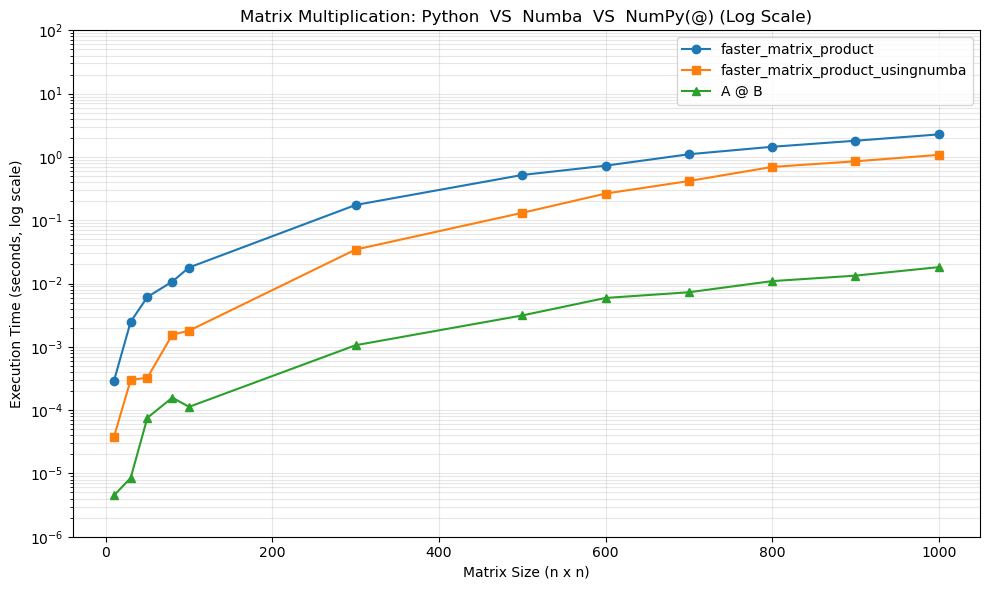

In [42]:
# Additional plot with a logarithmic y-axis
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, python_times, marker='o',
         label='faster_matrix_product')

plt.plot(sizes_part2, numba_times, marker='s',
         label='faster_matrix_product_usingnumba')

plt.plot(sizes_part2, numpy_times, marker='^',
         label='A @ B')

# Use a logarithmic scale to show all three curves clearly
plt.yscale('log')
plt.ylim(1e-6, 100)

plt.xlabel('Matrix Size (n x n)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Matrix Multiplication: Python  VS  Numba  VS  NumPy(@) (Log Scale)')

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

### If I want to make the line chart linear, I may make the Matrix Size axis into log format.⬇️

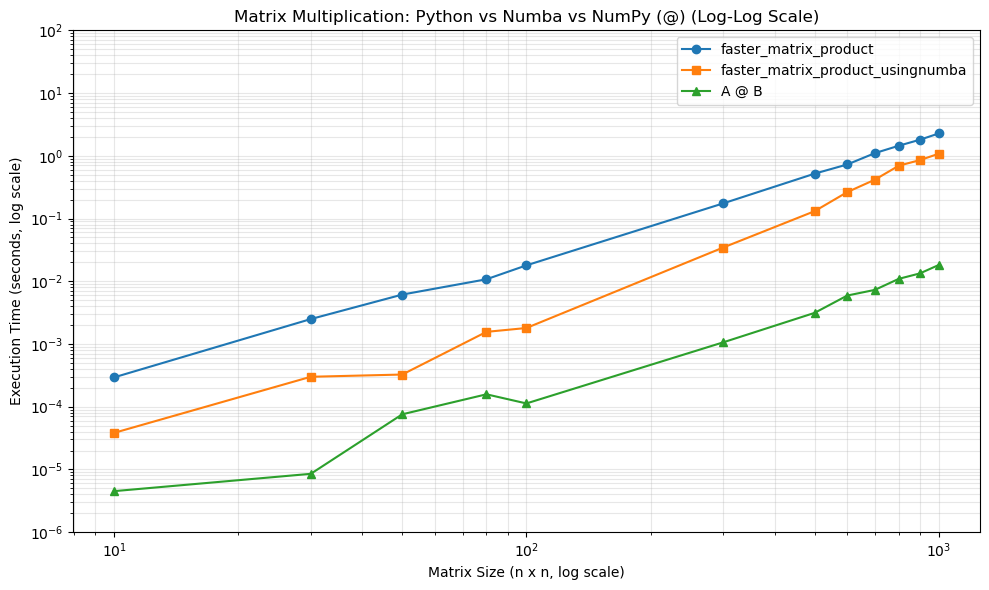

In [43]:
# Additional plot with logarithmic scales on both axes
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, python_times, marker='o',
         label='faster_matrix_product')

plt.plot(sizes_part2, numba_times, marker='s',
         label='faster_matrix_product_usingnumba')

plt.plot(sizes_part2, numpy_times, marker='^',
         label='A @ B')

plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-6, 100)

plt.xlabel('Matrix Size (n x n, log scale)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Matrix Multiplication: Python vs Numba vs NumPy (@) (Log-Log Scale)')

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

---

## **2.3 Adjust Memory Layout**

#### Ask for AI about how to get the asfortranarray function

In [44]:
# Create two random matrices
A = np.random.rand(100, 100)
B = np.random.rand(100, 100)

# C-order arrays
A_C = A
B_C = B

# Fortran-order arrays
A_F = np.asfortranarray(A)
B_F = np.asfortranarray(B)

# Check memory layout
print("A_C:", A_C.flags['C_CONTIGUOUS'])
print("A_F:", A_F.flags['F_CONTIGUOUS'])
print("B_C:", B_C.flags['C_CONTIGUOUS'])
print("B_F:", B_F.flags['F_CONTIGUOUS'])

A_C: True
A_F: True
B_C: True
B_F: True


In [45]:
# Four memory layout combinations in 100x100 matrix
layouts = {
    'CC': (A_C, B_C),
    'CF': (A_C, B_F),
    'FC': (A_F, B_C),
    'FF': (A_F, B_F)
}

# Warm up Numba and check correctness
for name, (mat1, mat2) in layouts.items():
    result = faster_matrix_product_usingnumba(mat1, mat2)
    assert np.allclose(result, mat1 @ mat2)

# Measure execution time
for name, (mat1, mat2) in layouts.items():
    t = measure_time(faster_matrix_product_usingnumba, mat1, mat2)
    print(f"{name}: {t:.6f} seconds")

CC: 0.002660 seconds
CF: 0.000711 seconds
FC: 0.003687 seconds
FF: 0.001661 seconds


In [46]:
# Store execution times for each memory layout
layout_times = {
    'CC': [],
    'CF': [],
    'FC': [],
    'FF': []
}

for n in sizes_part2:
    A = np.random.rand(n, n)
    B = np.random.rand(n, n)

    A_C = A
    B_C = B

    A_F = np.asfortranarray(A)
    B_F = np.asfortranarray(B)

    layouts = {
        'CC': (A_C, B_C),
        'CF': (A_C, B_F),
        'FC': (A_F, B_C),
        'FF': (A_F, B_F)
    }

    # Warm up and measure each layout
    for name, (mat1, mat2) in layouts.items():
        faster_matrix_product_usingnumba(mat1, mat2)

        t = measure_time(
            faster_matrix_product_usingnumba, mat1, mat2
        )

        layout_times[name].append(t)

    print(
        f"{n}x{n} matrix: "
        f"CC={layout_times['CC'][-1]:.6f}s, "
        f"CF={layout_times['CF'][-1]:.6f}s, "
        f"FC={layout_times['FC'][-1]:.6f}s, "
        f"FF={layout_times['FF'][-1]:.6f}s",
    )

10x10 matrix: CC=0.000031s, CF=0.000011s, FC=0.000045s, FF=0.000033s
30x30 matrix: CC=0.000300s, CF=0.000083s, FC=0.000408s, FF=0.000191s
50x50 matrix: CC=0.000369s, CF=0.000096s, FC=0.000471s, FF=0.000402s
80x80 matrix: CC=0.001053s, CF=0.000357s, FC=0.001752s, FF=0.001158s
100x100 matrix: CC=0.001828s, CF=0.000532s, FC=0.002841s, FF=0.002118s
300x300 matrix: CC=0.028820s, CF=0.005983s, FC=0.044540s, FF=0.026717s
500x500 matrix: CC=0.123651s, CF=0.028046s, FC=0.239830s, FF=0.119535s
600x600 matrix: CC=0.217131s, CF=0.058006s, FC=0.427554s, FF=0.217927s
700x700 matrix: CC=0.395201s, CF=0.073694s, FC=0.728575s, FF=0.405060s
800x800 matrix: CC=0.660752s, CF=0.113651s, FC=1.332453s, FF=0.778862s
900x900 matrix: CC=0.850147s, CF=0.158189s, FC=1.723617s, FF=0.879501s
1000x1000 matrix: CC=1.173451s, CF=0.234238s, FC=5.413574s, FF=1.269584s


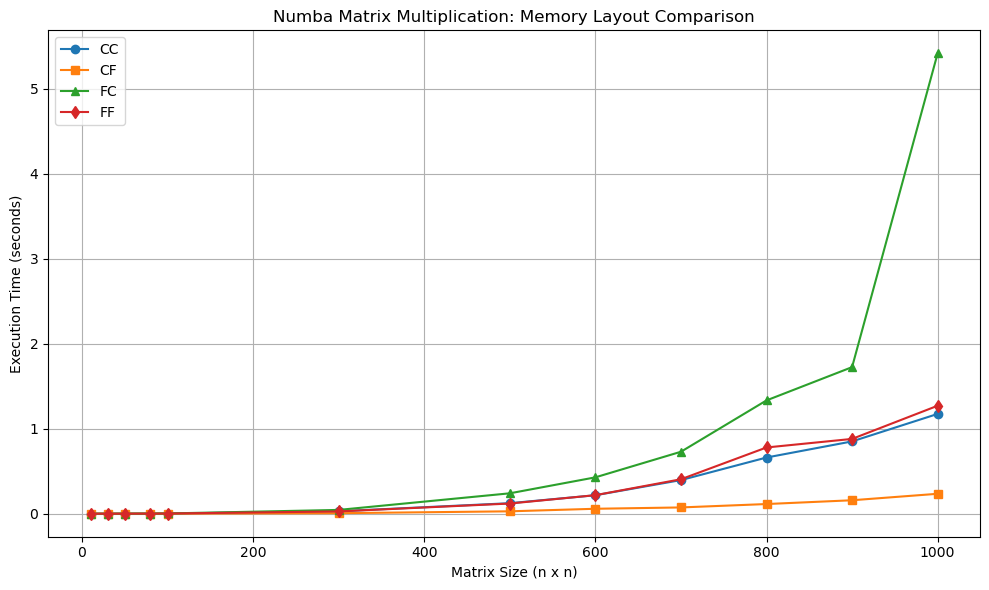

In [47]:
# Plot memory layout performance comparison
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, layout_times['CC'],
         marker='o', label='CC')

plt.plot(sizes_part2, layout_times['CF'],
         marker='s', label='CF')

plt.plot(sizes_part2, layout_times['FC'],
         marker='^', label='FC')

plt.plot(sizes_part2, layout_times['FF'],
         marker='d', label='FF')

plt.xlabel('Matrix Size (n x n)')
plt.ylabel('Execution Time (seconds)')
plt.title('Numba Matrix Multiplication: Memory Layout Comparison')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

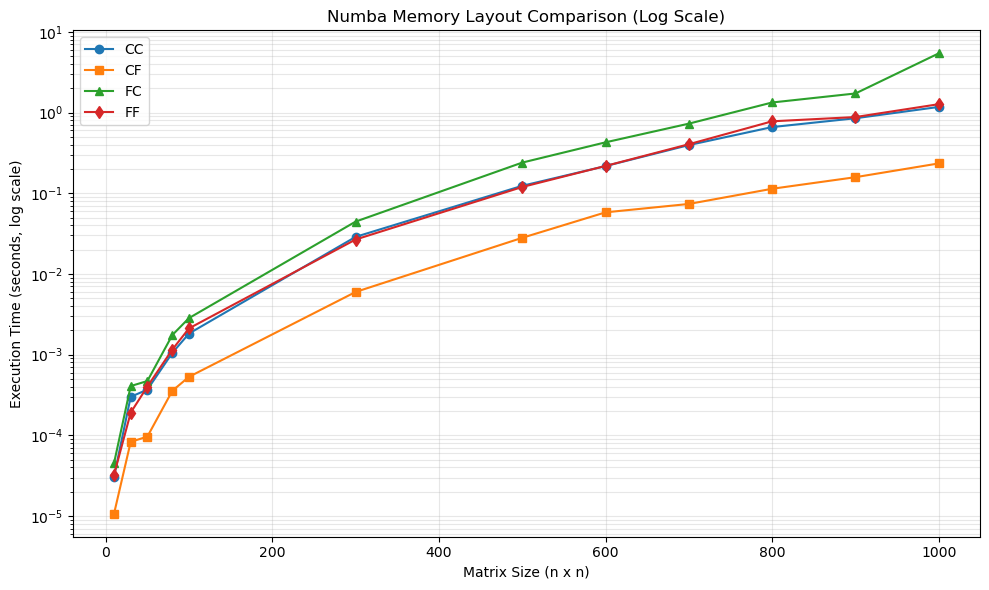

In [48]:
# Compare memory layouts using a logarithmic y-axis
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, layout_times['CC'],
         marker='o', label='CC')

plt.plot(sizes_part2, layout_times['CF'],
         marker='s', label='CF')

plt.plot(sizes_part2, layout_times['FC'],
         marker='^', label='FC')

plt.plot(sizes_part2, layout_times['FF'],
         marker='d', label='FF')

plt.yscale('log')

plt.xlabel('Matrix Size (n x n)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Numba Memory Layout Comparison (Log Scale)')

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

### If I want to make the line chart linear, I may make the Matrix Size axis into log format.⬇️

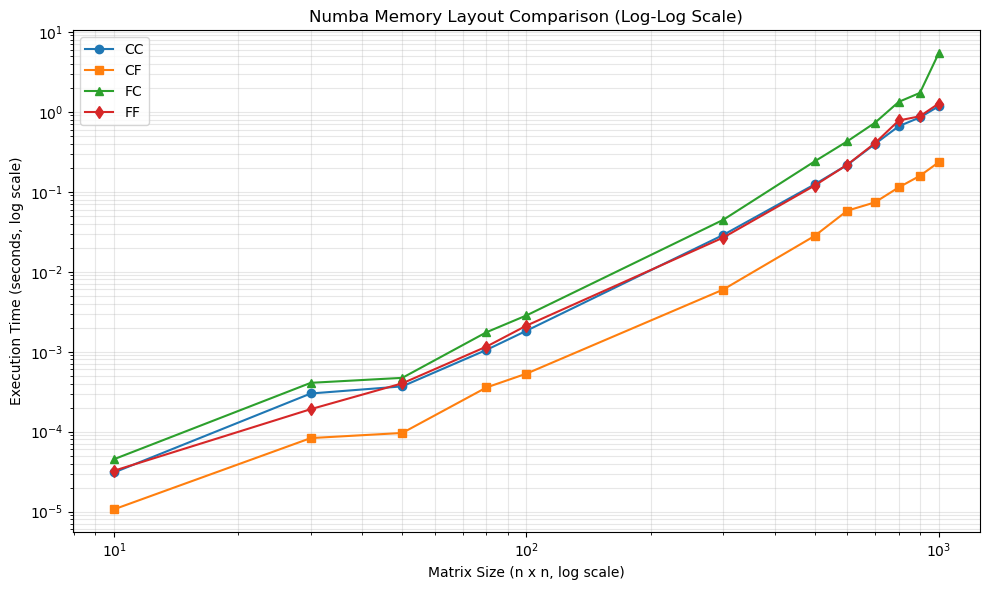

In [49]:
# Compare memory layouts using logarithmic scales on both axes
plt.figure(figsize=(10, 6))

plt.plot(sizes_part2, layout_times['CC'],
         marker='o', label='CC')

plt.plot(sizes_part2, layout_times['CF'],
         marker='s', label='CF')

plt.plot(sizes_part2, layout_times['FC'],
         marker='^', label='FC')

plt.plot(sizes_part2, layout_times['FF'],
         marker='d', label='FF')

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Matrix Size (n x n, log scale)')
plt.ylabel('Execution Time (seconds, log scale)')
plt.title('Numba Memory Layout Comparison (Log-Log Scale)')

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## **2.4 Analysis**


**From the figure, we can find the C-order and F-order memory layout has the shortest execution time among 4 results, the F-order and C-order memory layout has the longest time, and the execution times of CC and FF are similar.**

**Due to the reason that CF can contiguously store the rows of 1st matrix and the columns of the 2nd matrix, the elements are close in memory, making them to be read in the most fast way.**

**CC and FF have the similar execution time, since both of their layouts offer contiguous access that to the only 1 of the 2 input vectors. In CC, the rows of the 1st matrix are contiguous, but the columns of the 2nd matrix are not contiguous. And in FF, the case is converse, the rows of the 1st matrix are not contiguous, but the columns of the 2nd matrix are contiguous. Thus, both layouts only involve one contiguous access pattern, which may result in similar performance.**

**We can find that FC is the slowest because neither the rows of the 1st matrix, and nor the columns of the 2nd matrix are stored contiguously. This will make the memory access for both of the vectors, which may reduce the efficiency and increase the overhead of the dot-product operation.**

**Overall, the result shows that memory layout can affect the execution time.**